# Heart Disease Referral Alerting

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    precision_recall_curve
)

plt.style.use('seaborn-v0_8-whitegrid')


## Load the Dataset

In [2]:
url = "https://raw.githubusercontent.com/AndreasPr/Heart-Disease-Prediction-System/master/processed.cleveland.data.csv"

columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

# '?' marks missing values in the original UCI file
df = pd.read_csv(url, names=columns, na_values="?")

# Binarize target: 0 = no disease, 1 = disease present (any severity)
df["target"] = (df["target"] > 0).astype(int)

print("First 5 rows:")
df.head()


First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Dataset Size

In [3]:
print(f"Number of patients: {len(df)}")
print(f"Number of features: {df.shape[1] - 1}")


Number of patients: 303
Number of features: 13


## Check Missing Values

In [4]:
# Missing values per column
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


## Fill Missing Values with Mode

In [5]:
# Fill missing values with the mode (most frequent value)
for col in ["ca", "thal"]:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum().sum())

0


## Encode Categorical Features

In [6]:
# Convert codes to int so column names are clean (cp_2, not cp_2.0)
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    df[col] = df[col].astype(int)

# One-hot encode nominal columns
df_encoded = pd.get_dummies(df, columns=["cp", "restecg", "slope", "thal"], drop_first=True, dtype=int)

print(df.shape[1], df_encoded.shape[1])

14 19


## Target Distribution

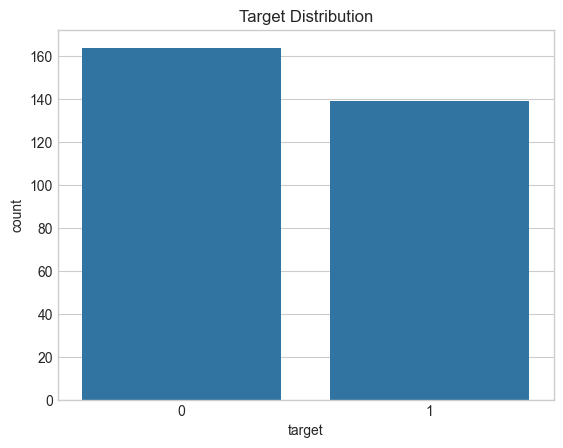

target
0    0.541254
1    0.458746
Name: proportion, dtype: float64


In [7]:
sns.countplot(x="target", data=df_encoded)
plt.title("Target Distribution")
plt.show()

print(df_encoded["target"].value_counts(normalize=True))

## Feature Distributions

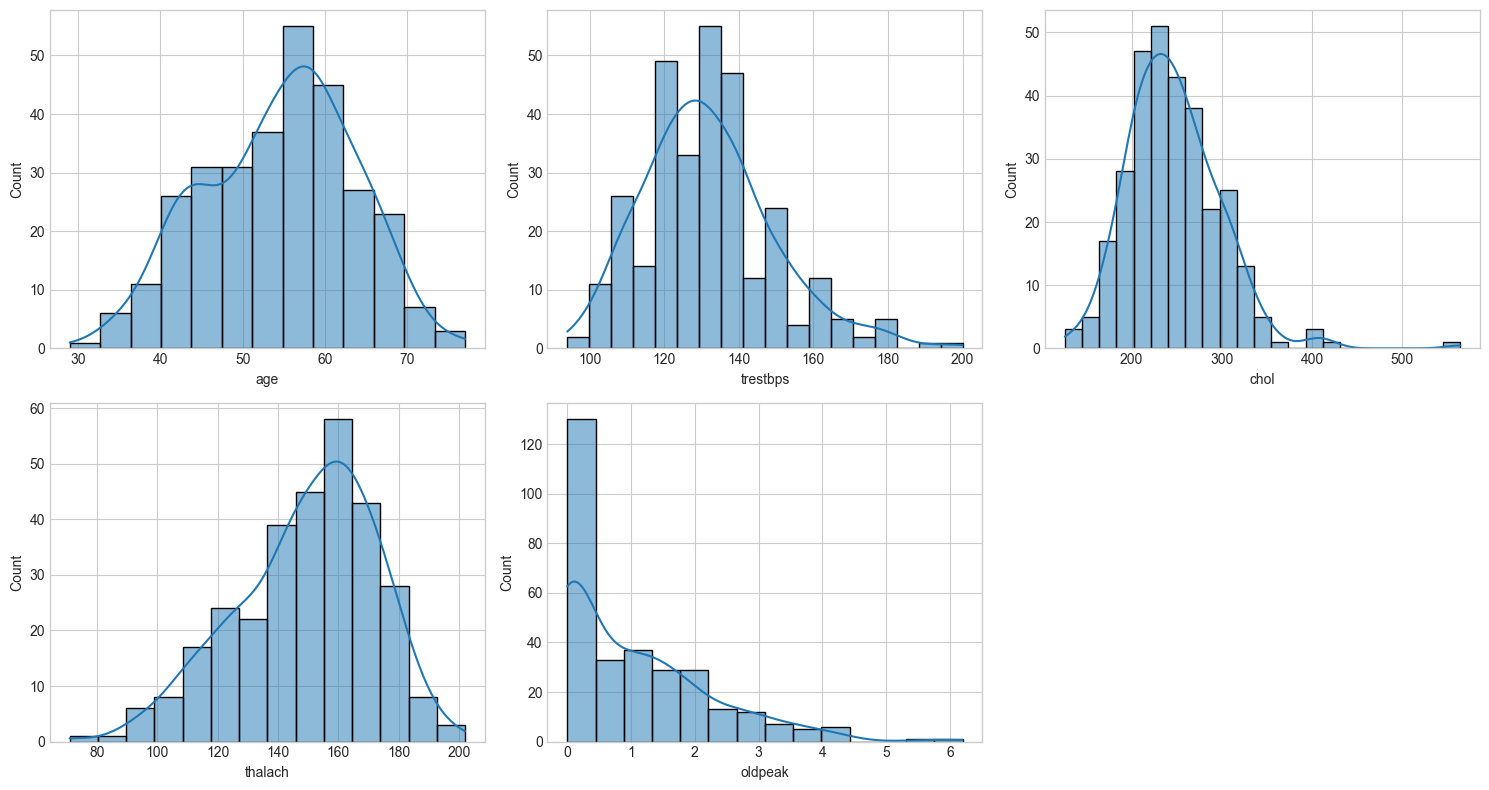

In [8]:
cont = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cont):
    sns.histplot(df_encoded[col], kde=True, ax=ax)
axes.flat[5].axis("off")
plt.tight_layout()
plt.show()

## Outliers (Boxplots)

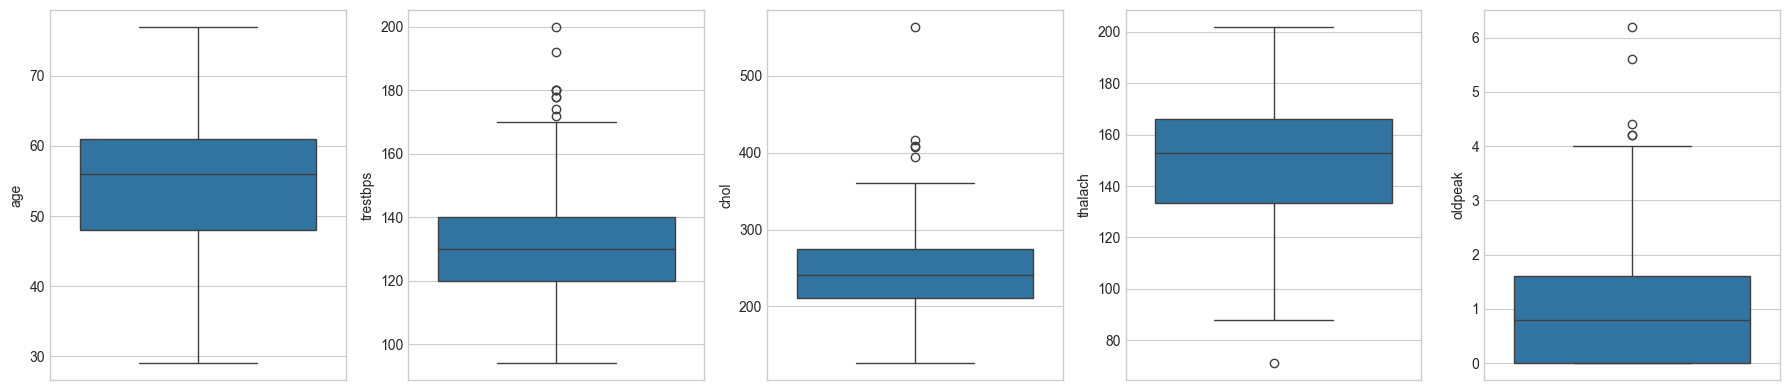

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, cont):
    sns.boxplot(y=df_encoded[col], ax=ax)
plt.tight_layout()
plt.show()

## Correlation Matrix

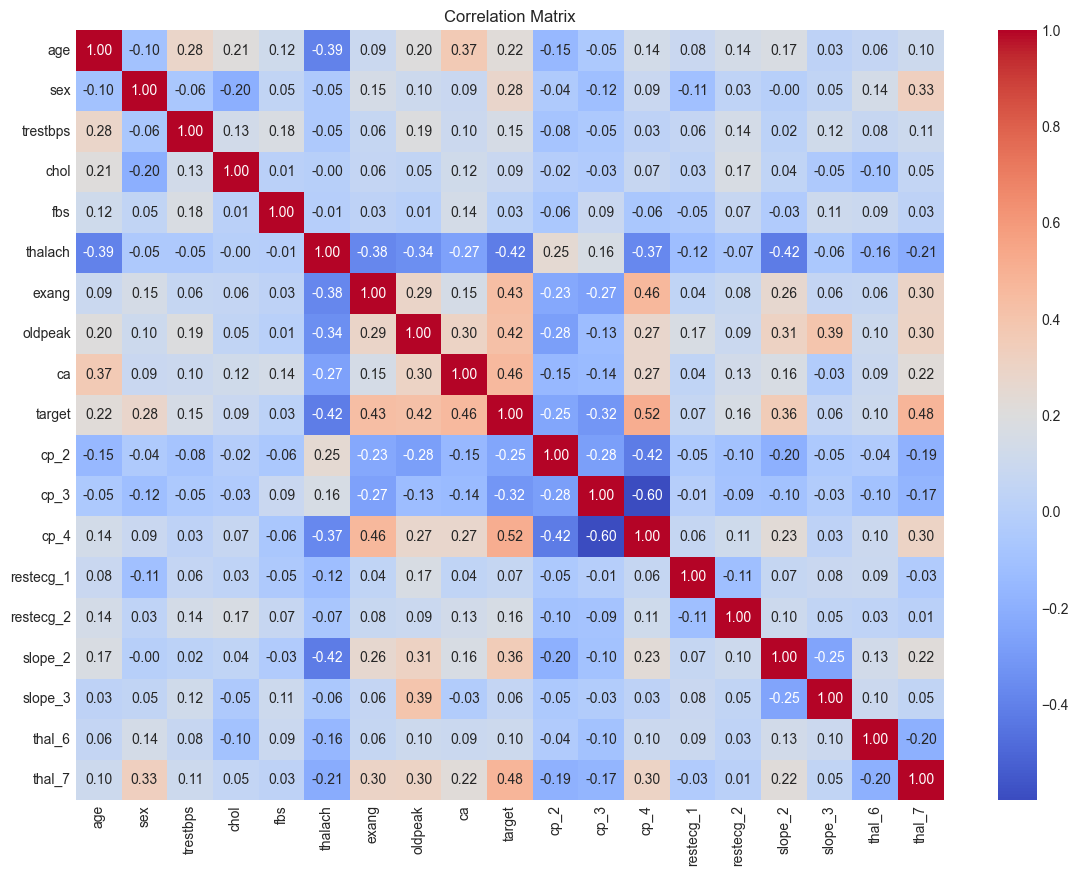

thalach     -0.417167
cp_3        -0.315141
cp_2        -0.248683
fbs          0.025264
slope_3      0.061710
restecg_1    0.067605
chol         0.085164
thal_6       0.104864
trestbps     0.150825
restecg_2    0.160400
age          0.223120
sex          0.276816
slope_2      0.355709
oldpeak      0.424510
exang        0.431894
ca           0.460033
thal_7       0.480582
cp_4         0.516459
target       1.000000
Name: target, dtype: float64


In [10]:
plt.figure(figsize=(14, 10))
sns.heatmap(df_encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

print(df_encoded.corr()["target"].sort_values())

## Train-Test Split

In [11]:
X = df_encoded.drop("target", axis=1)
y = df_encoded["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## Feature Scaling

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Train Logistic Regression Model

In [13]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

coef = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_[0]})
print(coef.sort_values("Coefficient", ascending=False))

      Feature  Coefficient
8          ca     1.153034
11       cp_4     0.869874
1         sex     0.737149
17     thal_7     0.680931
14    slope_2     0.598590
2    trestbps     0.353672
9        cp_2     0.340218
6       exang     0.272919
3        chol     0.201367
13  restecg_2     0.198869
7     oldpeak     0.192704
15    slope_3     0.074526
10       cp_3     0.064135
16     thal_6     0.018031
0         age    -0.064349
4         fbs    -0.089844
12  restecg_1    -0.131138
5     thalach    -0.357175


## Predictions and Accuracy

In [14]:
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.819672131147541


## Confusion Matrix

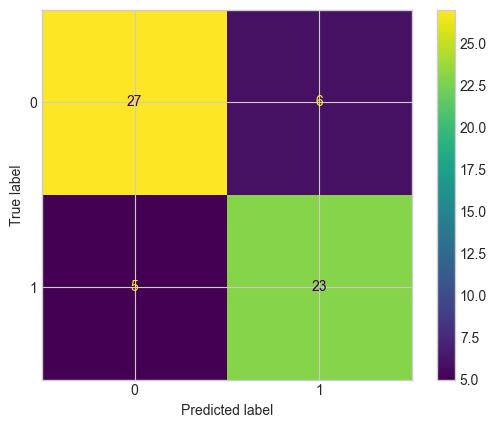

In [15]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot()
plt.show()

## Classification Report

In [16]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.82      0.83        33
           1       0.79      0.82      0.81        28

    accuracy                           0.82        61
   macro avg       0.82      0.82      0.82        61
weighted avg       0.82      0.82      0.82        61



## ROC Curve and AUC

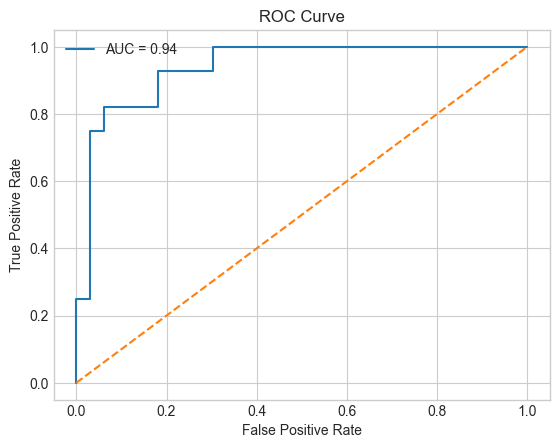

In [17]:
auc = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## Precision, Recall and Referral Rate vs Threshold

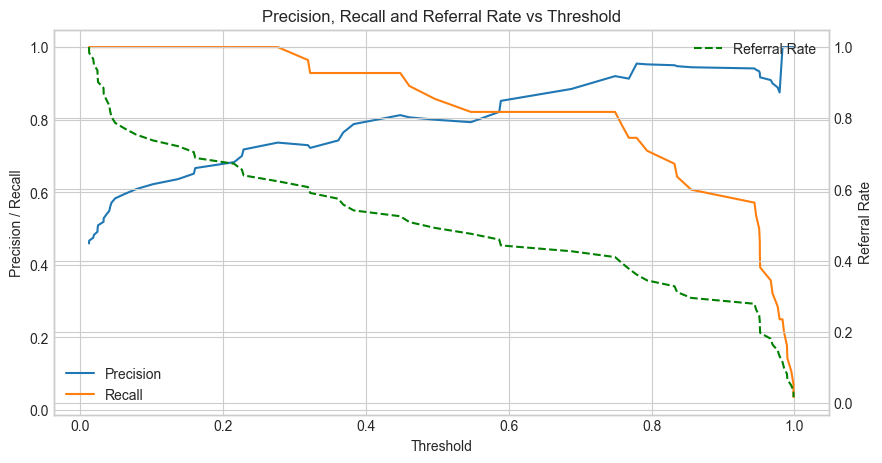

In [18]:
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, y_pred_proba)

referral_rates = [(y_pred_proba >= t).mean() for t in pr_thresholds]

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(pr_thresholds, precisions[:-1], label="Precision")
ax1.plot(pr_thresholds, recalls[:-1], label="Recall")
ax1.set_xlabel("Threshold")
ax1.set_ylabel("Precision / Recall")
ax1.legend(loc="lower left")

ax2 = ax1.twinx()
ax2.plot(pr_thresholds, referral_rates, "g--", label="Referral Rate")
ax2.set_ylabel("Referral Rate")
ax2.legend(loc="upper right")

plt.title("Precision, Recall and Referral Rate vs Threshold")
plt.show()

## Results at Chosen Threshold

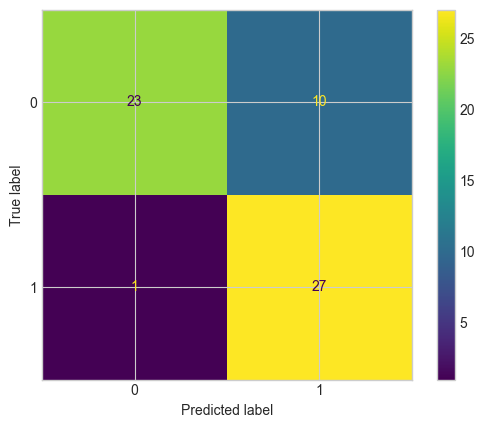

              precision    recall  f1-score   support

           0       0.96      0.70      0.81        33
           1       0.73      0.96      0.83        28

    accuracy                           0.82        61
   macro avg       0.84      0.83      0.82        61
weighted avg       0.85      0.82      0.82        61

Referral rate: 0.6065573770491803


In [19]:
my_threshold = 0.3

y_pred_new = (y_pred_proba >= my_threshold).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_new)).plot()
plt.show()

print(classification_report(y_test, y_pred_new))
print("Referral rate:", y_pred_new.mean())

## Sample Patients

In [20]:
sample_patients = pd.DataFrame([
    {  # Profile A: several risk factors present
        "age": 62, "sex": 1, "trestbps": 152, "chol": 275, "fbs": 0,
        "thalach": 118, "exang": 1, "oldpeak": 2.4, "ca": 2,
        "cp_2": 0, "cp_3": 0, "cp_4": 1,
        "restecg_1": 0, "restecg_2": 1,
        "slope_2": 1, "slope_3": 0,
        "thal_6": 0, "thal_7": 1,
    },
    {  # Profile B: mostly low risk factors
        "age": 41, "sex": 0, "trestbps": 118, "chol": 190, "fbs": 0,
        "thalach": 172, "exang": 0, "oldpeak": 0.2, "ca": 0,
        "cp_2": 1, "cp_3": 0, "cp_4": 0,
        "restecg_1": 0, "restecg_2": 0,
        "slope_2": 0, "slope_3": 0,
        "thal_6": 0, "thal_7": 0,
    },
    {  # Profile C: borderline / mixed signals
        "age": 55, "sex": 1, "trestbps": 130, "chol": 233, "fbs": 1,
        "thalach": 150, "exang": 0, "oldpeak": 1.0, "ca": 0,
        "cp_2": 0, "cp_3": 1, "cp_4": 0,
        "restecg_1": 0, "restecg_2": 0,
        "slope_2": 1, "slope_3": 0,
        "thal_6": 0, "thal_7": 0,
    },
])[X.columns]  # ensure column order matches training data


## Predictions for Sample Patients

In [21]:
sample_scaled = scaler.transform(sample_patients)
probs = model.predict_proba(sample_scaled)[:, 1]

results = pd.DataFrame({
    "Patient": ["A", "B", "C"],
    "Predicted Probability": probs.round(3),
    "Alert at 0.5 (default)": probs >= 0.5,
    f"Alert at {my_threshold}": probs >= my_threshold,
})
results

,Patient,Predicted Probability,Alert at 0.5 (default),Alert at 0.3
0,A,0.998,True,True
1,B,0.012,False,False
2,C,0.134,False,False
